In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib import animation, rc

import numpy as np
from collections import namedtuple
from IPython.display import HTML

plt.style.use('seaborn-whitegrid')

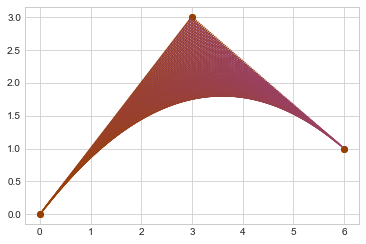

In [32]:
# setup our figure to plot on
fig, ax = plt.subplots()


# define an abstraction for holding points
Point = namedtuple('Point', ['x', 'y'])

# the points we want to interpolate between
p0 = Point(0, 0)
p1 = Point(3, 3)
p2 = Point(6, 1)
line, = ax.plot([], [])

def interpolate(p0, p1, x):
    # interpolates a corresponding `y` value
    # for a given `x` value between [p0.x, p1.x].
    assert(p0.x <= p1.x)
    assert(x >= p0.x)
    assert(x <= p1.x)
    top = p0.y*(p1.x - x) + p1.y*(x - p0.x)
    bot = p1.x - p0.x
    return top/bot

def lerp(v0, v1, t):
    # lerp takes two values v0 and v1 and a value 
    # t between [0, 1] and returns the t-percent
    # value between [v0, v1]
    assert(t >=0 and t <= 1)
    return v0 + t * (v1 - v0)

# initialize our animation with the three points
def init():
    points, = ax.plot([p0.x, p1.x, p2.x], [p0.y, p1.y, p2.y], 'o', color='#994000')
    return (points,)

# at each frame, draw the line between the ith lerp `t` value
# for the line between P0 and P1 and the line between P1 and P2.
def animate(i):
    t = i/100
    P1x = lerp(p0.x, p1.x, t)
    P1y = lerp(p0.y, p1.y, t)
    P2x = lerp(p1.x, p2.x, t)
    P2y = lerp(p1.y, p2.y, t)
    line, = ax.plot([P1x, P2x], [P1y, P2y], '#994%03x' % i)
    return (line,)

# animate!
anim = animation.FuncAnimation(fig, animate, init_func=init,
                               frames=100, interval=100, blit=True)
HTML(anim.to_html5_video())